# 04. RQ4, where adaptation helps and where it hurts

> Reference notebook. Every number below is produced by the same functions that
> write the paper's tables (`paper_resources/scripts/`), so this is a readable
> view of the pipeline rather than a second implementation. Regenerate the
> `.tex` files with `python scripts/run_all.py`.


**Question.** Adaptation is not a uniform improvement, so which tasks and which
languages gain, and which pay?

Backs the verdict marks in Table 2, Table A11 (tests against the base model),
Table A13 (resource tiers), Table A14 (cross-benchmark check), and Figure 1.


In [1]:
import sys
from pathlib import Path

import pandas as pd

REPO_ROOT = next(p for p in Path.cwd().resolve().parents if (p / "paper_resources").is_dir())
sys.path.insert(0, str(REPO_ROOT / "paper_resources" / "scripts"))

import common as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
# 4 significant digits rather than 4 decimals, so that a p-value of 5.6e-15 stays
# readable next to an effect size of 0.94.
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

cfg = C.load_config()
BENCHMARKS = cfg["analysis"]["benchmarks"]
ALPHA = cfg["analysis"]["alpha"]
print(f"repo root : {REPO_ROOT}")
print(f"benchmarks: {BENCHMARKS}")
print(f"alpha     : {ALPHA}")

repo root : /data/upb/users/n/nikit/profiles/unix/cs/projects/moe-study-analysis
benchmarks: ['Belebele', 'FLORES', 'SIB200', 'Taxi1500']
alpha     : 0.05


In [2]:
baseline = cfg["rq3"]["baseline_run_id"]
regimes = cfg["rq3"]["regimes"]
groups = cfg["rq3"]["resource_groups"]
panels = {r: C.load_final_panel(C.results_path(cfg, f"final_{r}_xlsx"), cfg) for r in regimes}
labels = {baseline: cfg["rq3"]["baseline_label"]}
labels.update({e["run_id"]: e["label"] for e in cfg["rq3"]["finalists"]})

## Two benchmarks on two incomparable scales

Belebele is accuracy. FLORES is bits per byte over reference translations, a
*per byte* quantity, so its absolute differences are small by construction. A
raw median difference of `0.006` next to `3.4 accuracy points` invites a
comparison that is not meaningful.

`baseline_magnitudes` puts each difference back on a scale a reader can judge,
namely the base model's own level, the relative change, the win rate, and, where
a random-guess floor is well defined, the share of the margin above chance.


In [3]:
tests = {r: C.final_pairwise_tests(panels[r], BENCHMARKS) for r in regimes}
verdicts = {
    r: C.verdict_vs_baseline(tests[r], baseline, ALPHA).set_index(["method", "benchmark"])
    for r in regimes
}
magnitudes = {
    r: C.baseline_magnitudes(
        panels[r], baseline, BENCHMARKS, cfg["analysis"].get("chance_levels")
    ).set_index(["method", "benchmark"])
    for r in regimes
}
vs_baseline = pd.concat(
    {r: verdicts[r].join(magnitudes[r].drop(columns="median_difference")) for r in regimes},
    names=["regime"],
).reset_index()
vs_baseline["method"] = vs_baseline["method"].map(labels)
vs_baseline.head()

,regime,method,benchmark,median_difference,rank_biserial,p_holm,verdict,n_cases,base_median,median_relative_gain_pct,win_rate_pct,median_gain_vs_headroom_pct
0,96,HydraLoRA r2,Belebele,-0.01667,-0.8154,9.985e-05,worse,40,0.4606,-3.652,15,-7.916
1,96,MOELoRA r2/16 k8,Belebele,-0.02,-0.8476,3.586e-05,worse,40,0.4606,-3.459,15,-9.499
2,96,MOELoRA r2/32 k8,Belebele,-0.02278,-0.8205,0.0001038,worse,40,0.4606,-4.093,17.5,-10.82
3,96,AdaMoE r2/8 k6,Belebele,-0.03444,-0.9463,2.75e-06,worse,40,0.4606,-5.74,12.5,-16.36
4,96,MTL-LoRA r8/16,Belebele,-0.025,-0.8718,2.918e-05,worse,40,0.4606,-4.484,12.5,-11.87


### Belebele, where adaptation consistently costs reading comprehension

All ten configuration-regime combinations are significantly worse than the base
model.


In [4]:
cols = ["regime", "method", "median_difference", "rank_biserial", "p_holm",
        "verdict", "base_median", "win_rate_pct", "median_gain_vs_headroom_pct"]
vs_baseline.query("benchmark == 'Belebele'")[cols]

,regime,method,median_difference,rank_biserial,p_holm,verdict,base_median,win_rate_pct,median_gain_vs_headroom_pct
0,96,HydraLoRA r2,-0.01667,-0.8154,9.985e-05,worse,0.4606,15,-7.916
1,96,MOELoRA r2/16 k8,-0.02,-0.8476,3.586e-05,worse,0.4606,15,-9.499
2,96,MOELoRA r2/32 k8,-0.02278,-0.8205,0.0001038,worse,0.4606,17.5,-10.82
3,96,AdaMoE r2/8 k6,-0.03444,-0.9463,2.75e-06,worse,0.4606,12.5,-16.36
4,96,MTL-LoRA r8/16,-0.025,-0.8718,2.918e-05,worse,0.4606,12.5,-11.87
20,200,HydraLoRA r2,-0.02333,-0.9189,1.548e-09,worse,0.4467,9.231,-11.86
21,200,MOELoRA r2/16 k8,-0.02444,-0.9758,1.196e-10,worse,0.4467,4.615,-12.43
22,200,MOELoRA r2/32 k8,-0.01778,-0.8597,1.854e-08,worse,0.4467,13.85,-9.04
23,200,AdaMoE r2/8 k6,-0.03444,-0.9857,2.094e-10,worse,0.4467,4.615,-17.51
24,200,MTL-LoRA r8/16,-0.02222,-0.8986,4.929e-09,worse,0.4467,15.38,-11.3


The regression is 1.7 to 3.4 accuracy points, which is roughly **8 to 18% of the
base model's margin above chance** (Belebele is four-way multiple choice, so
chance is 0.25). That is real without being a collapse, and the headroom column
is what makes it judgeable.


### FLORES, where the gain is small in absolute terms and large in consistency


In [5]:
cols = ["regime", "method", "median_difference", "rank_biserial", "p_holm",
        "verdict", "base_median", "median_relative_gain_pct", "win_rate_pct"]
vs_baseline.query("benchmark == 'FLORES'")[cols]

,regime,method,median_difference,rank_biserial,p_holm,verdict,base_median,median_relative_gain_pct,win_rate_pct
5,96,HydraLoRA r2,0.004745,0.7275,2.949e-09,better,0.4676,1.015,78
6,96,MOELoRA r2/16 k8,0.00592,0.9374,5.602e-15,better,0.4676,1.203,88
7,96,MOELoRA r2/32 k8,0.006414,0.9846,1.884e-16,better,0.4676,1.28,96
8,96,AdaMoE r2/8 k6,0.005567,0.7937,7.232e-11,better,0.4676,1.118,78
9,96,MTL-LoRA r8/16,0.005837,0.7826,1.308e-10,better,0.4676,1.207,81
25,200,HydraLoRA r2,0.006404,0.8065,2.82e-18,better,0.4854,1.444,83.73
26,200,MOELoRA r2/16 k8,0.0006271,0.1683,0.12,tie,0.4854,0.1478,57.23
27,200,MOELoRA r2/32 k8,0.001877,0.4025,4.807e-05,better,0.4854,0.4131,62.65
28,200,AdaMoE r2/8 k6,0.005952,0.7207,8.072e-15,better,0.4854,1.287,78.31
29,200,MTL-LoRA r8/16,0.002262,0.2546,0.01332,better,0.4854,0.5357,62.05


Against a base median near 0.5 bits per byte, a median gain of 0.002 to 0.006 is
a **0.4 to 1.4% relative reduction**. The rank-biserial effect is the quantity
that compares fairly across benchmarks, because it uses only the direction and
the relative size of each per-case difference, with no units at all.

At **96** languages the FLORES effects (+0.73 to +0.98, with 78 to 96% of cases
improving) mirror the Belebele ones (-0.82 to -0.95), so the benefit is as
consistent as the regression. At **200** it attenuates and becomes
method-dependent. HydraLoRA and AdaMoE hold up (+0.81 and +0.72) while the other
three shrink towards zero (+0.17 to +0.40).


### How to read a rank-biserial effect

Drop ties, rank the per-case differences by *absolute* size, then compare the
rank mass on each side with `(R+ - R-) / (R+ + R-)`. It is the share of ranked
evidence favouring the system minus the share against, so +1 means it won every
case and 0 means wins and losses cancel.

It is not a win rate. A plain win rate treats a hair-thin loss like a crushing
one, and this does not. That is why a system can win 81% of cases and still
score +0.78 rather than 2(0.81) - 1 = +0.62, if its losses are the small ones.


In [6]:
flores96 = panels[96].query("benchmark == 'FLORES'")
scores = flores96.pivot(index=C.UNIT_COLS, columns="run_id", values="score")
method = "mtllora_lr5e5_r8_nup16"
gain = scores[method] - scores[baseline]

print(f"{labels[method]}, FLORES, 96 training languages")
print(f"  cases            : {len(gain)}")
print(f"  win rate         : {100 * (gain > 0).mean():.0f}%")
print(f"  naive 2p-1 score : {2 * (gain > 0).mean() - 1:+.2f}")
print(f"  rank-biserial    : {C.rank_biserial(scores[method], scores[baseline]):+.2f}")
print("\nThe gap is the point: its losses sit among the smallest differences.")
print(f"  median |diff| when winning: {gain[gain > 0].abs().median():.5f}")
print(f"  median |diff| when losing : {gain[gain < 0].abs().median():.5f}")

MTL-LoRA r8/16, FLORES, 96 training languages
  cases            : 100
  win rate         : 81%
  naive 2p-1 score : +0.62
  rank-biserial    : +0.78

The gap is the point: its losses sit among the smallest differences.
  median |diff| when winning: 0.00798
  median |diff| when losing : 0.00323


### SIB-200 and Taxi1500

In [7]:
vs_baseline.query("benchmark in ['SIB200', 'Taxi1500']")[
    ["regime", "method", "benchmark", "median_difference", "rank_biserial", "p_holm", "verdict"]
]

,regime,method,benchmark,median_difference,rank_biserial,p_holm,verdict
10,96,HydraLoRA r2,SIB200,0.004902,0.008296,1,tie
11,96,MOELoRA r2/16 k8,SIB200,-0,-0.09388,1,tie
12,96,MOELoRA r2/32 k8,SIB200,0.03431,0.75,5.445e-05,better
13,96,AdaMoE r2/8 k6,SIB200,-0.02941,-0.5239,0.006305,worse
14,96,MTL-LoRA r8/16,SIB200,-0.04412,-0.5953,0.001488,worse
15,96,HydraLoRA r2,Taxi1500,-0,-0.3626,0.1798,tie
16,96,MOELoRA r2/16 k8,Taxi1500,0.02703,0.8962,2.373e-07,better
17,96,MOELoRA r2/32 k8,Taxi1500,-0,0.2029,0.6549,tie
18,96,AdaMoE r2/8 k6,Taxi1500,0.009009,0.2278,0.5949,tie
19,96,MTL-LoRA r8/16,Taxi1500,0.01802,0.5562,0.003374,better


SIB-200 is where the methods actually separate, with outcomes running from
significantly better to significantly worse depending on configuration and
regime. Taxi1500 mostly cannot distinguish the systems at all.


## Which languages gain?

The per-language gain is plotted against how well the base model already handled
that language. A downward slope means adaptation *redistributes* capability
rather than adding it uniformly.


In [8]:
import fig2_rq4_gain_vs_base as fig2

trends = pd.read_csv(C.output_dir(cfg, "data") / "fig2_rq4_gain_vs_base.csv")
trends

,regime,benchmark,n_languages,spearman_rho,p_value
0,96,Belebele,40,-0.64,8.73e-06
1,96,FLORES,50,-0.7284,2.028e-09
2,96,SIB-200,51,-0.8015,1.595e-12
3,96,Taxi1500,58,-0.1594,0.2321
4,200,Belebele,65,-0.6683,1.183e-09
5,200,FLORES,83,-0.5531,5.896e-08
6,200,SIB-200,84,-0.7349,1.74e-15
7,200,Taxi1500,93,-0.383,0.0001512


In [9]:
frame = fig2.gain_frame(panels[96], baseline, "FLORES")
print("one row per language: base score, mean gain over the five promoted configurations")
frame.head(10).round(4)

one row per language: base score, mean gain over the five promoted configurations


,base,gain,tier
language,,,
als_Latn,-0.4278,0.0085,MEDIUM
arb_Arab,-0.3355,0.0035,HIGH
arb_Latn,-1.321,0.0129,LOW
ayr_Latn,-1.716,0.0138,LOW
azj_Latn,-0.5602,0.0071,MEDIUM
bod_Tibt,-0.6528,0.0131,LOW
cmn_Hani,-0.4159,-0.0001,HIGH
deu_Latn,-0.2764,0.0033,HIGH
dyu_Latn,-1.817,0.018,LOW


The line slopes downward in seven of the eight panels, with rho between -0.55
and -0.80 on Belebele, FLORES and SIB-200 in both regimes. Adaptation gives most
to the languages the base model served worst.


Rebuilt inline from the same `gain_frame` and `draw_panel` helpers that write
Figure 1, so what renders here is the figure in the paper rather than a picture
of it. Weaker base model to the left in every panel. Points above the grey line
are languages adaptation improved.


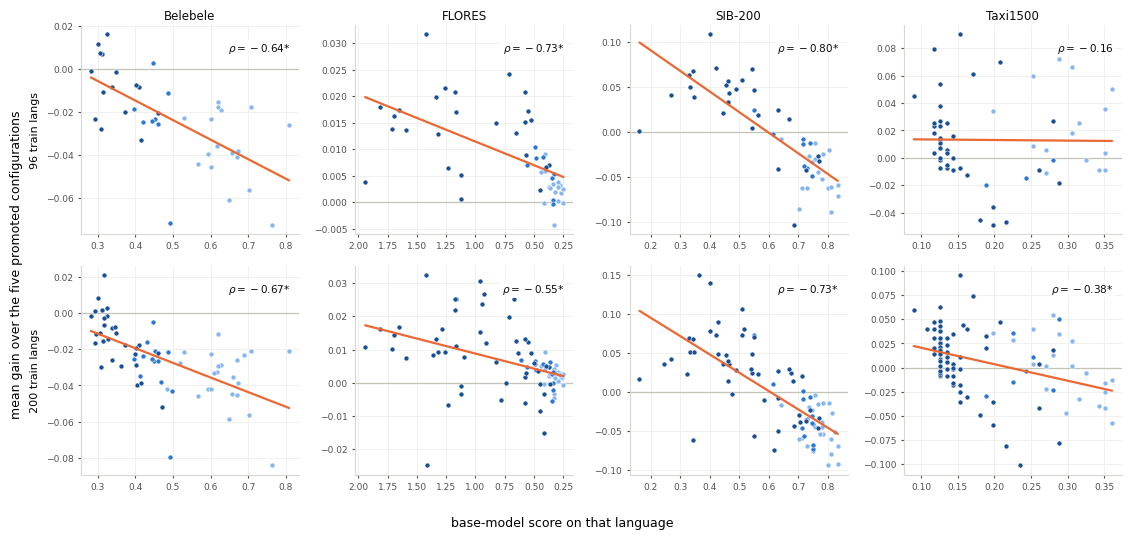

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

figure, grid = plt.subplots(len(regimes), len(BENCHMARKS), figsize=(11.5, 5.4))
for row, regime in enumerate(regimes):
    for col, benchmark in enumerate(BENCHMARKS):
        rho, p_value = fig2.draw_panel(
            grid[row][col],
            fig2.gain_frame(panels[regime], baseline, benchmark),
            C.benchmark_label(benchmark) if row == 0 else None,
            flip_x=(benchmark == "FLORES"),
        )
    grid[row][0].set_ylabel(f"{regime} train langs", fontsize=8)
figure.supxlabel("base-model score on that language", fontsize=9)
figure.supylabel("mean gain over the five promoted configurations", fontsize=9)
figure.tight_layout()
plt.show()

### Two checks on that trend

**Shared noise.** The base score appears on both axes, so the correlation could
be an artefact. Predicting the gain on one benchmark from the base score on a
*different* benchmark, where the measurement noise is independent, keeps the
relationship.


In [11]:
pd.read_csv(C.output_dir(cfg, "data") / "tabA4_rq4_cross_benchmark.csv").round(3)

,regime,gain_on,base_from,n_languages,spearman_rho,p_value
0,96,Belebele,FLORES,38,-0.491,0.002
1,96,Belebele,SIB200,39,-0.485,0.002
2,96,Belebele,Taxi1500,27,-0.632,0
3,96,FLORES,Belebele,38,-0.556,0
4,96,FLORES,SIB200,50,-0.471,0.001
5,96,FLORES,Taxi1500,29,-0.551,0.002
6,96,SIB200,Belebele,39,-0.674,0
7,96,SIB200,FLORES,50,-0.737,0
8,96,SIB200,Taxi1500,30,-0.501,0.005
9,96,Taxi1500,Belebele,27,0.066,0.744


**Scale.** The trend is measured on absolute scores, and on FLORES the weakest
languages have the most room to move simply because bits per byte is unbounded
above. The same comparison on a *relative* scale is what tells a real
low-resource advantage apart from the dynamic range of the metric.


In [12]:
absolute = pd.read_csv(C.output_dir(cfg, "data") / "tab8_rq4_resource.csv")
print("Percentage of evaluation cases won against the base model (all benchmarks):")
display(absolute.round(1))

relative = pd.read_csv(
    C.output_dir(cfg, "data") / "tab8b_rq4_flores_relative_by_resource.csv"
)
print("\nMedian *relative* FLORES gain (%), by resource tier:")
relative.round(2)

Percentage of evaluation cases won against the base model (all benchmarks):


,regime,resource_availability,hydralora_r2,moelora_tr32_e16_k8,moelora_tr64_e32_k8,mola_tr16_e8_k6,mtllora_lr5e5_r8_nup16
0,96,HIGH,32.1,49.4,58,33.3,39.5
1,96,LOW,61.7,76.7,68.4,66.2,69.9
2,96,MEDIUM,51.4,60,65.7,40,40
3,200,HIGH,50.9,35.5,36.4,39.1,40.9
4,200,LOW,68.6,41.4,61.1,59,58.2
5,200,MEDIUM,54.2,40.7,27.1,44.1,42.4



Median *relative* FLORES gain (%), by resource tier:


,regime,resource_availability,hydralora_r2,moelora_tr32_e16_k8,moelora_tr64_e32_k8,mola_tr16_e8_k6,mtllora_lr5e5_r8_nup16
0,96,HIGH,0.17,0.67,0.79,0.58,0.61
1,96,MEDIUM,1.11,1.24,1.15,1.38,1.3
2,96,LOW,1.04,1.37,1.46,1.25,1.45
3,200,HIGH,1.26,0.26,0.12,1.07,0.76
4,200,MEDIUM,1.65,0.28,-0.12,1.5,0.51
5,200,LOW,1.5,-0.01,0.93,1.27,0.26


At **96** training languages the direction survives on a relative scale. The
median FLORES gain is 1.1 to 1.4% for low-resource languages against 0.8 to
1.2% for high-resource ones, and low-resource leads for all five configurations.
At **200** the tier ordering disappears.

So the claim that adaptation benefits lower-resource languages most is well
supported on the absolute win rates and at 96 languages in relative terms, and
should not be stated unconditionally for FLORES at 200.


## What survives

Nothing here is randomized, so all of it is a consistent association rather than
a causal effect. And because each configuration is trained **once**, these tests
describe consistency across evaluation cases rather than uncertainty across
training runs. A large effect says the result held across languages, not that a
different seed would reproduce it.

What generalizes is the *direction* of the effect rather than which method
delivers it. Adaptation improves language-model fit on translation data,
consistently costs reading comprehension, and separates methods on topic
classification. That is a targeted tool rather than a general upgrade.
